In [ ]:

from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:

import os

PROJECT_PATH = "/content/drive/MyDrive/Marketing-Campaign-Prediction"

print(os.listdir(PROJECT_PATH))


['notebooks']


In [ ]:

import os

DATASET_PATH = "/content/drive/MyDrive/Marketing-Campaign-Prediction/dataset"

os.makedirs(DATASET_PATH, exist_ok=True)

print("Dataset folder created successfully!")


Dataset folder created successfully!


In [ ]:

import requests
import zipfile
import os

url = "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip"

zip_path = os.path.join(DATASET_PATH, "bank-marketing.zip")

response = requests.get(url)
response.raise_for_status()

with open(zip_path, "wb") as file:
    file.write(response.content)

print("Dataset downloaded successfully!")


Dataset downloaded successfully!


In [ ]:

# Extract bank.zip from the downloaded ZIP

with zipfile.ZipFile(zip_path, 'r') as outer_zip:
    outer_zip.extract("bank.zip", DATASET_PATH)

print("Inner ZIP extracted successfully!")


Inner ZIP extracted successfully!


In [ ]:

inner_zip_path = os.path.join(DATASET_PATH, "bank.zip")

with zipfile.ZipFile(inner_zip_path, 'r') as inner_zip:
    print("Files inside bank.zip:")
    print(inner_zip.namelist())

    inner_zip.extract("bank-full.csv", DATASET_PATH)

print("Dataset extracted successfully!")


Files inside bank.zip:
['bank-full.csv', 'bank-names.txt', 'bank.csv']
Dataset extracted successfully!


In [ ]:

import pandas as pd
import os

file_path = os.path.join(DATASET_PATH, "bank-full.csv")

df = pd.read_csv(file_path, sep=';')

print("Dataset loaded successfully!")
print("\nDataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nFirst 5 Records:")
display(df.head())


Dataset loaded successfully!

Dataset Shape: (45211, 17)

Column Names:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']

First 5 Records:


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [3]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [4]:
import pandas as pd
import os

DATASET_PATH = "/content/drive/MyDrive/Marketing-Campaign-Prediction/dataset"

file_path = os.path.join(DATASET_PATH, "bank-full.csv")

df = pd.read_csv(file_path, sep=';')

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (45211, 17)


In [5]:

# DAY 1 - PHASE 2: DATA QUALITY ANALYSIS

# 1. Dataset Information
print("========== DATASET INFORMATION ==========")
df.info()


# 2. Missing Values
print("\n========== MISSING VALUES ==========")
print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())


# 3. Duplicate Records
print("\n========== DUPLICATE RECORDS ==========")
print("Total duplicate records:", df.duplicated().sum())


# 4. Statistical Summary
print("\n========== STATISTICAL SUMMARY ==========")
display(df.describe())


# 5. Target Variable Distribution
print("\n========== TARGET VARIABLE DISTRIBUTION ==========")
print(df['y'].value_counts())

print("\nTarget Percentage:")
print(df['y'].value_counts(normalize=True) * 100)


# 6. Unknown Values
print("\n========== UNKNOWN VALUES ==========")

categorical_cols = df.select_dtypes(include='object').columns

for col in categorical_cols:
    count = (df[col] == 'unknown').sum()
    if count > 0:
        print(f"{col}: {count}")


========== DATASET INFORMATION ==========
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB

========== MISSING VALUES ==========
age          0
job 

,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000



========== TARGET VARIABLE DISTRIBUTION ==========
y
no     39922
yes     5289
Name: count, dtype: int64

Target Percentage:
y
no     88.30152
yes    11.69848
Name: proportion, dtype: float64

========== UNKNOWN VALUES ==========
job: 288
education: 1857
contact: 13020
poutcome: 36959


In [6]:

# Investigating numerical outliers

numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns

for col in numerical_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]

    print(f"\nFeature: {col}")
    print("Lower limit:", lower)
    print("Upper limit:", upper)
    print("Potential outliers:", len(outliers))



Feature: age
Lower limit: 10.5
Upper limit: 70.5
Potential outliers: 487

Feature: balance
Lower limit: -1962.0
Upper limit: 3462.0
Potential outliers: 4729

Feature: day
Lower limit: -11.5
Upper limit: 40.5
Potential outliers: 0

Feature: duration
Lower limit: -221.0
Upper limit: 643.0
Potential outliers: 3235

Feature: campaign
Lower limit: -2.0
Upper limit: 6.0
Potential outliers: 3064

Feature: pdays
Lower limit: -1.0
Upper limit: -1.0
Potential outliers: 8257

Feature: previous
Lower limit: 0.0
Upper limit: 0.0
Potential outliers: 8257


In [7]:
print("pdays value counts:")
print(df['pdays'].value_counts().head(10))

print("\nprevious value counts:")
print(df['previous'].value_counts().head(10))

print("\nNumber of customers never contacted before:")
print((df['pdays'] == -1).sum())

pdays value counts:
pdays
-1      36954
 182      167
 92       147
 183      126
 91       126
 181      117
 370       99
 184       85
 364       77
 95        74
Name: count, dtype: int64

previous value counts:
previous
0    36954
1     2772
2     2106
3     1142
4      714
5      459
6      277
7      205
8      129
9       92
Name: count, dtype: int64

Number of customers never contacted before:
36954


In [9]:
import os

PROJECT_PATH = "/content/drive/MyDrive/Marketing-Campaign-Prediction"

GRAPH_PATH = os.path.join(PROJECT_PATH, "results", "graphs")
os.makedirs(GRAPH_PATH, exist_ok=True)

print("Graph folder created:", GRAPH_PATH)

Graph folder created: /content/drive/MyDrive/Marketing-Campaign-Prediction/results/graphs


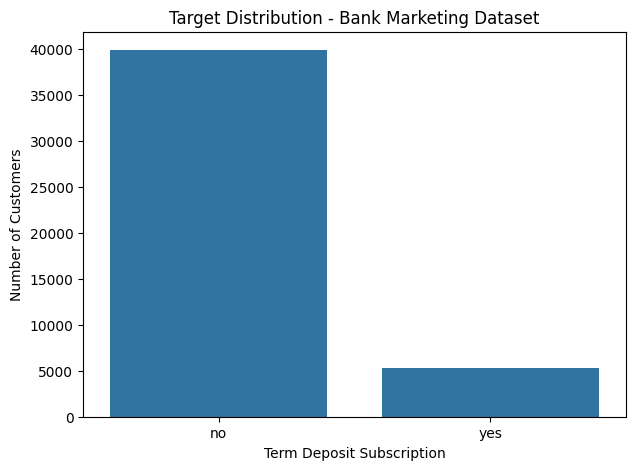

In [10]:
import os
import matplotlib.pyplot as plt
import seaborn as sns

# Create folder for saving graphs
GRAPH_PATH = os.path.join(PROJECT_PATH, "results", "graphs")
os.makedirs(GRAPH_PATH, exist_ok=True)

# Target distribution
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='y')

plt.title("Target Distribution - Bank Marketing Dataset")
plt.xlabel("Term Deposit Subscription")
plt.ylabel("Number of Customers")

plt.savefig(
    os.path.join(GRAPH_PATH, "target_distribution.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

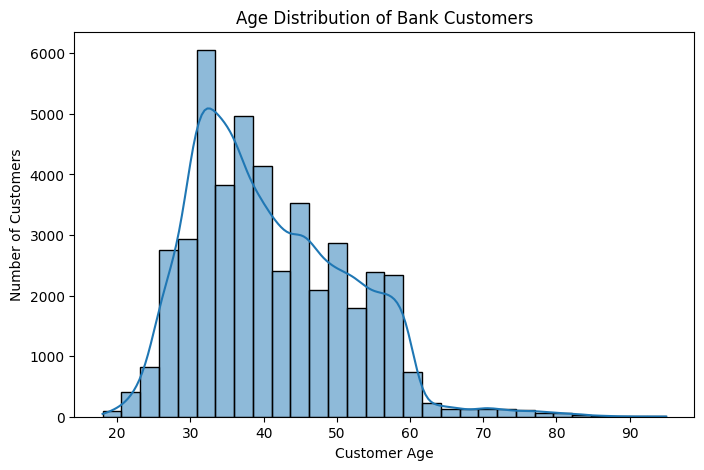

In [11]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x='age', bins=30, kde=True)

plt.title("Age Distribution of Bank Customers")
plt.xlabel("Customer Age")
plt.ylabel("Number of Customers")

plt.savefig(
    os.path.join(GRAPH_PATH, "age_distribution.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

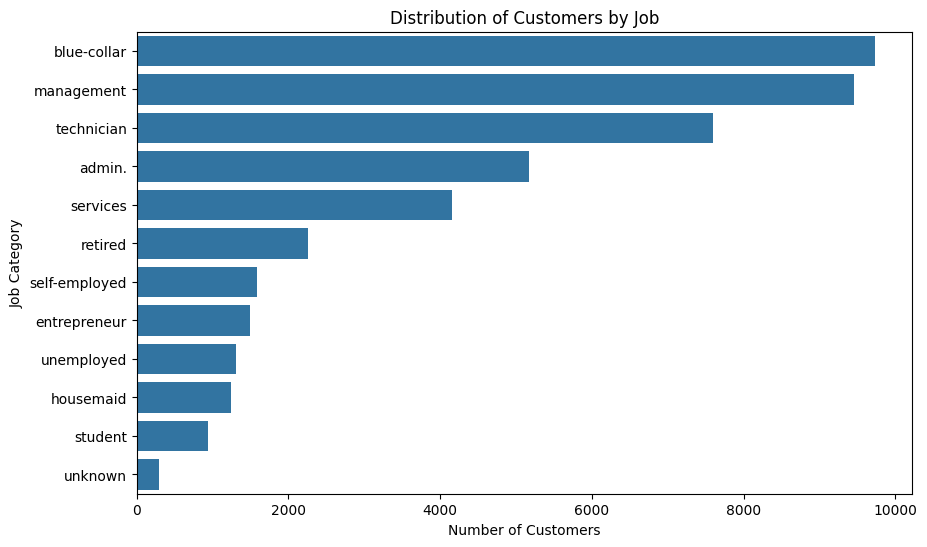

In [12]:
plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    y='job',
    order=df['job'].value_counts().index
)

plt.title("Distribution of Customers by Job")
plt.xlabel("Number of Customers")
plt.ylabel("Job Category")

plt.savefig(
    os.path.join(GRAPH_PATH, "job_distribution.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

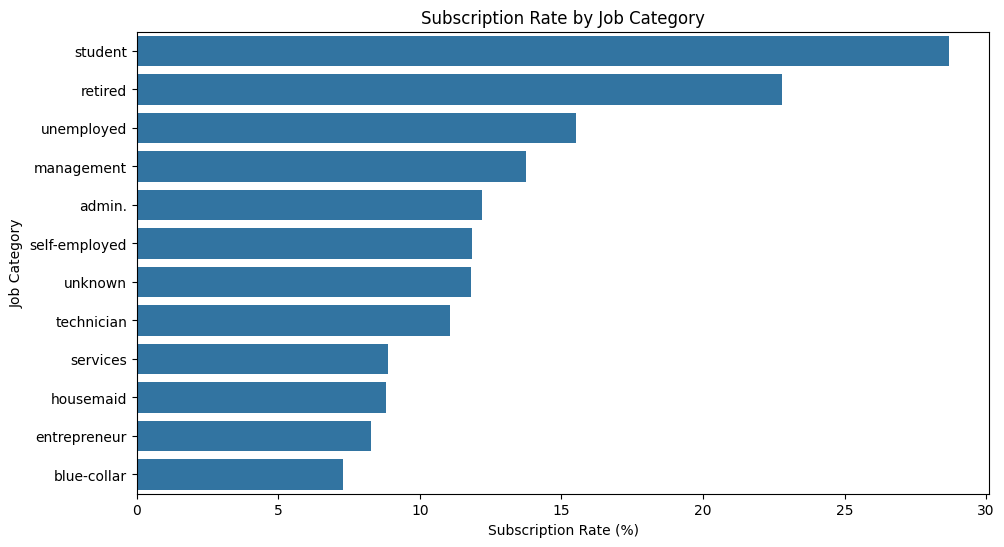

In [13]:
plt.figure(figsize=(11, 6))

job_subscription = (
    df.groupby('job')['y']
    .apply(lambda x: (x == 'yes').mean() * 100)
    .sort_values(ascending=False)
)

sns.barplot(
    x=job_subscription.values,
    y=job_subscription.index
)

plt.title("Subscription Rate by Job Category")
plt.xlabel("Subscription Rate (%)")
plt.ylabel("Job Category")

plt.savefig(
    os.path.join(GRAPH_PATH, "subscription_by_job.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


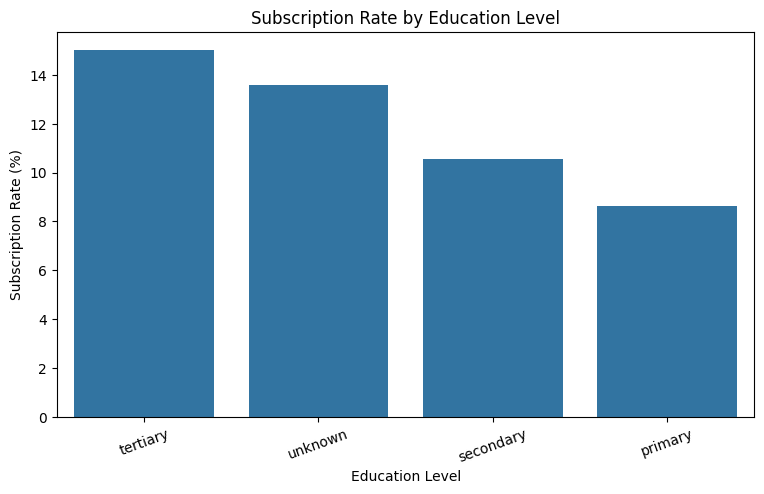

In [14]:
education_subscription = (
    df.groupby('education')['y']
    .apply(lambda x: (x == 'yes').mean() * 100)
    .sort_values(ascending=False)
)

plt.figure(figsize=(9, 5))

sns.barplot(
    x=education_subscription.index,
    y=education_subscription.values
)

plt.title("Subscription Rate by Education Level")
plt.xlabel("Education Level")
plt.ylabel("Subscription Rate (%)")
plt.xticks(rotation=20)

plt.savefig(
    os.path.join(GRAPH_PATH, "subscription_by_education.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

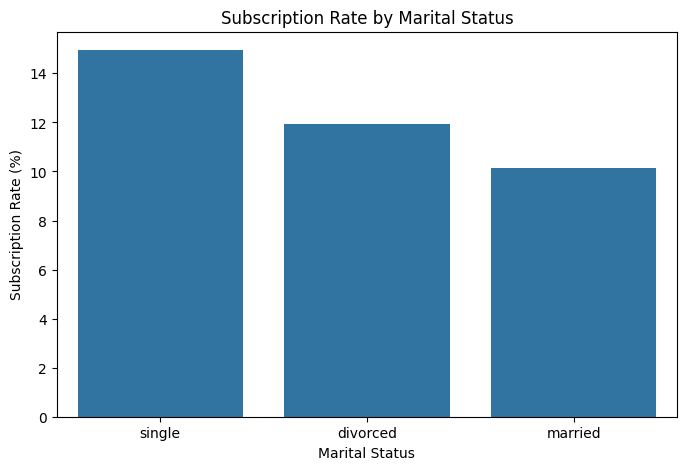

In [15]:
marital_subscription = (
    df.groupby('marital')['y']
    .apply(lambda x: (x == 'yes').mean() * 100)
    .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=marital_subscription.index,
    y=marital_subscription.values
)

plt.title("Subscription Rate by Marital Status")
plt.xlabel("Marital Status")
plt.ylabel("Subscription Rate (%)")

plt.savefig(
    os.path.join(GRAPH_PATH, "subscription_by_marital.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

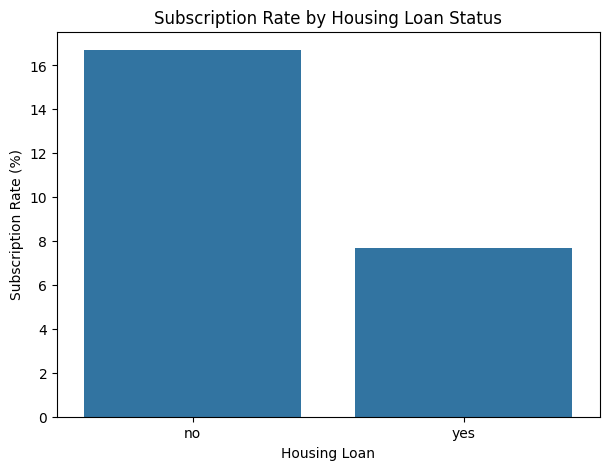

In [16]:
housing_subscription = (
    df.groupby('housing')['y']
    .apply(lambda x: (x == 'yes').mean() * 100)
)

plt.figure(figsize=(7, 5))

sns.barplot(
    x=housing_subscription.index,
    y=housing_subscription.values
)

plt.title("Subscription Rate by Housing Loan Status")
plt.xlabel("Housing Loan")
plt.ylabel("Subscription Rate (%)")

plt.savefig(
    os.path.join(GRAPH_PATH, "subscription_by_housing.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

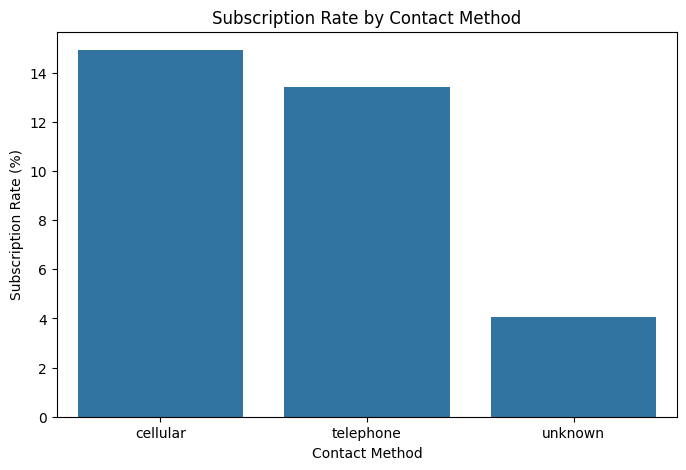

In [17]:
contact_subscription = (
    df.groupby('contact')['y']
    .apply(lambda x: (x == 'yes').mean() * 100)
    .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=contact_subscription.index,
    y=contact_subscription.values
)

plt.title("Subscription Rate by Contact Method")
plt.xlabel("Contact Method")
plt.ylabel("Subscription Rate (%)")

plt.savefig(
    os.path.join(GRAPH_PATH, "subscription_by_contact.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

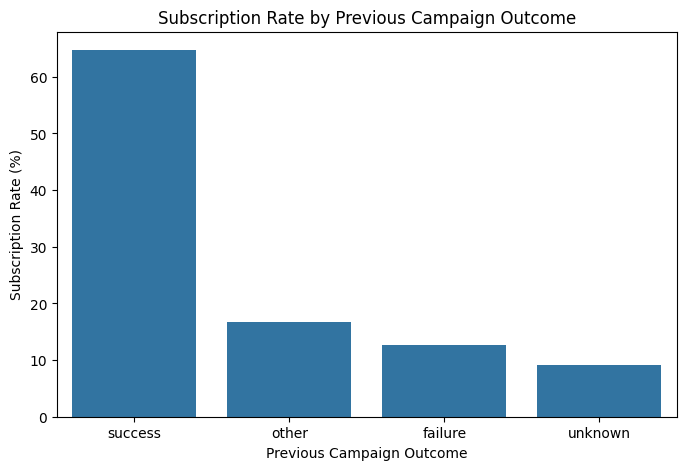

In [18]:
poutcome_subscription = (
    df.groupby('poutcome')['y']
    .apply(lambda x: (x == 'yes').mean() * 100)
    .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=poutcome_subscription.index,
    y=poutcome_subscription.values
)

plt.title("Subscription Rate by Previous Campaign Outcome")
plt.xlabel("Previous Campaign Outcome")
plt.ylabel("Subscription Rate (%)")

plt.savefig(
    os.path.join(GRAPH_PATH, "subscription_by_poutcome.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

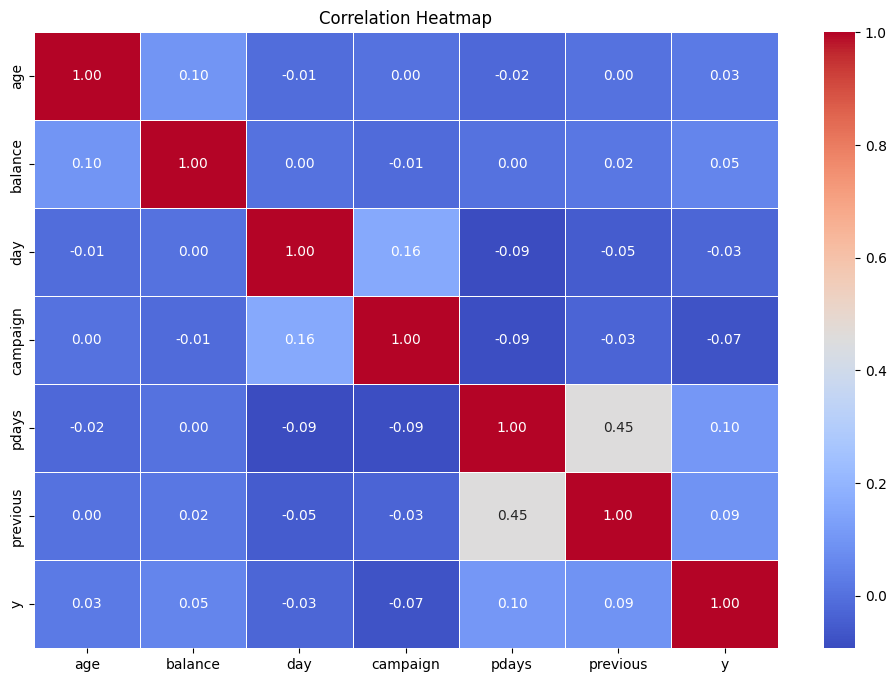

In [19]:
# Create a copy for correlation analysis
corr_df = df.copy()

# Convert target into numerical values
corr_df['y'] = corr_df['y'].map({'no': 0, 'yes': 1})

# Select numerical columns, excluding duration
corr_data = corr_df.select_dtypes(include='number').drop(columns=['duration'])

# Plot correlation heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(
    corr_data.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title("Correlation Heatmap")

plt.savefig(
    os.path.join(GRAPH_PATH, "correlation_heatmap.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

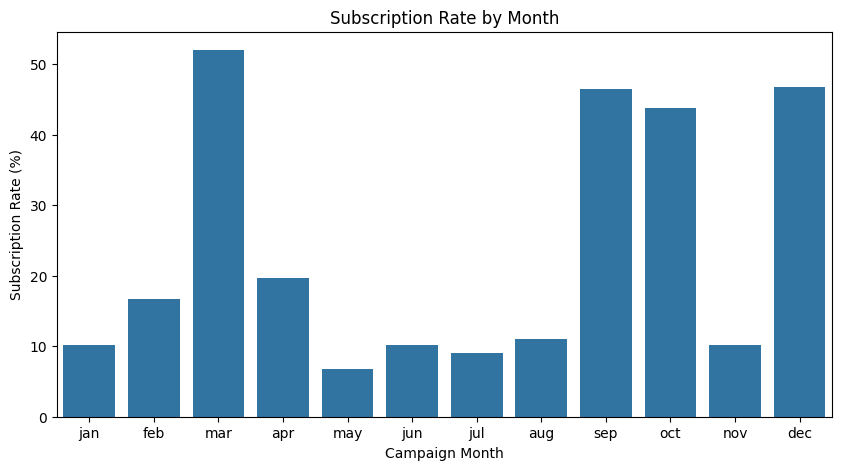

In [20]:
month_order = [
    'jan', 'feb', 'mar', 'apr', 'may', 'jun',
    'jul', 'aug', 'sep', 'oct', 'nov', 'dec'
]

month_subscription = (
    df.groupby('month')['y']
    .apply(lambda x: (x == 'yes').mean() * 100)
    .reindex(month_order)
)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=month_subscription.index,
    y=month_subscription.values
)

plt.title("Subscription Rate by Month")
plt.xlabel("Campaign Month")
plt.ylabel("Subscription Rate (%)")

plt.savefig(
    os.path.join(GRAPH_PATH, "subscription_by_month.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [21]:
# Separate features and target

X = df.drop(columns=['y', 'duration'])
y = df['y'].map({'no': 0, 'yes': 1})

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nInput features:")
print(X.columns.tolist())

print("\nTarget distribution:")
print(y.value_counts())

Features shape: (45211, 15)
Target shape: (45211,)

Input features:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'campaign', 'pdays', 'previous', 'poutcome']

Target distribution:
y
0    39922
1     5289
Name: count, dtype: int64


In [22]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training features: (36168, 15)
Testing features: (9043, 15)

Training target distribution:
y
0    88.301814
1    11.698186
Name: proportion, dtype: float64

Testing target distribution:
y
0    88.300343
1    11.699657
Name: proportion, dtype: float64


In [23]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

# Identify numerical and categorical columns
categorical_cols = X.select_dtypes(include='object').columns.tolist()
numerical_cols = X.select_dtypes(exclude='object').columns.tolist()

print("Categorical columns:", categorical_cols)
print("\nNumerical columns:", numerical_cols)

# Create encoder
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols),
        ('num', 'passthrough', numerical_cols)
    ]
)

# Fit on training data and transform both sets
X_train_encoded = preprocessor.fit_transform(X_train)
X_test_encoded = preprocessor.transform(X_test)

print("\nAfter encoding:")
print("Training shape:", X_train_encoded.shape)
print("Testing shape:", X_test_encoded.shape)

Categorical columns: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']

Numerical columns: ['age', 'balance', 'day', 'campaign', 'pdays', 'previous']

After encoding:
Training shape: (36168, 50)
Testing shape: (9043, 50)


In [24]:
from sklearn.preprocessing import StandardScaler
from scipy.sparse import issparse

# Convert encoded data to dense arrays
if issparse(X_train_encoded):
    X_train_encoded = X_train_encoded.toarray()
    X_test_encoded = X_test_encoded.toarray()

# Identify numerical feature positions
num_indices = [
    i for i, name in enumerate(preprocessor.get_feature_names_out())
    if name.startswith('num__')
]

# Scale numerical features for ANN
scaler = StandardScaler()

X_train_ann = X_train_encoded.copy()
X_test_ann = X_test_encoded.copy()

X_train_ann[:, num_indices] = scaler.fit_transform(
    X_train_encoded[:, num_indices]
)

X_test_ann[:, num_indices] = scaler.transform(
    X_test_encoded[:, num_indices]
)

# Random Forest uses unscaled encoded data
X_train_ml = X_train_encoded.copy()
X_test_ml = X_test_encoded.copy()

print("Random Forest training shape:", X_train_ml.shape)
print("ANN training shape:", X_train_ann.shape)
print("ANN testing shape:", X_test_ann.shape)

Random Forest training shape: (36168, 50)
ANN training shape: (36168, 50)
ANN testing shape: (9043, 50)


In [25]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

# Calculate class weights
classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight='balanced',
    classes=classes,
    y=y_train
)

class_weights = dict(zip(classes, weights))

print("Class weights:", class_weights)
print("\nClass 0 = No subscription")
print("Class 1 = Yes subscription")

Class weights: {np.int64(0): np.float64(0.5662397845758838), np.int64(1): np.float64(4.27416686362562)}

Class 0 = No subscription
Class 1 = Yes subscription


In [26]:
import joblib
import os

MODEL_PATH = os.path.join(PROJECT_PATH, "models")
os.makedirs(MODEL_PATH, exist_ok=True)

# Save preprocessing objects
joblib.dump(preprocessor, os.path.join(MODEL_PATH, "preprocessor.pkl"))
joblib.dump(scaler, os.path.join(MODEL_PATH, "scaler.pkl"))

# Save prepared datasets
joblib.dump(
    {
        "X_train_ml": X_train_ml,
        "X_test_ml": X_test_ml,
        "X_train_ann": X_train_ann,
        "X_test_ann": X_test_ann,
        "y_train": y_train,
        "y_test": y_test,
        "class_weights": class_weights
    },
    os.path.join(MODEL_PATH, "processed_data.pkl")
)

print("Preprocessing objects and datasets saved successfully!")


Preprocessing objects and datasets saved successfully!
